## Taxi Demand and Driver-Level Service Time Across One Day (Flag 4)

### Dataset Overview
The main table contains completed taxi request events with request, pickup, dropoff, waiting-time, passenger-trip-duration, driver, and service-channel fields. The secondary table contains one row per driver for the observed day and summarizes completed trips and waiting-time behavior.

The notebook exposes a primary table and a supporting table (`driver_day_summary.csv`).

Goal: Analyze the demand and service-time structure of taxi operations over one day, including how waiting and passenger-trip durations vary across drivers.

Role: Urban taxi demand and service analyst


Category: Overall Characterization

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trip_events.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "driver_day_summary.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the number of taxi requests change over the course of the day?

#### Analysis action

Compare the hourly demand profile before examining service-time differences.

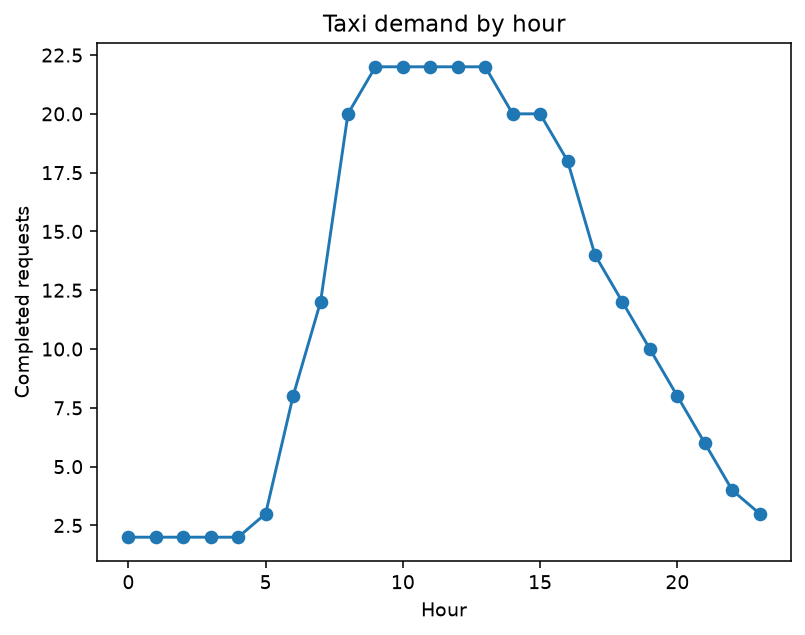

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d = pd.read_csv(dataset_path)
d['request_time'] = pd.to_datetime(d['request_time'])
d['hour'] = d['request_time'].dt.hour
counts = d.groupby('hour').size()
counts.reindex(range(24), fill_value=0).plot(kind='line', marker='o')
plt.title('Taxi demand by hour'); plt.xlabel('Hour'); plt.ylabel('Completed requests'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q1_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temporal",
  "insight": "Taxi demand is highest from 08:00 to 16:00 and reaches its lowest level during the early-morning hours.",
  "insight_value": {
    "highest_demand_period": "08:00–16:00",
    "lowest_demand_period": "00:00–05:00"
  },
  "plot": {
    "plot_type": "line_chart",
    "title": "Taxi Demand by Hour",
    "file": "notebook_plots/q1_1.png",
    "description": "The hourly number of completed taxi requests is plotted across the observed day."
  },
  "question": "How does the number of taxi requests change over the course of the day?",
  "actionable_insight": "Compare the hourly demand profile before examining service-time differences.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd = pd.read_csv('trip_events.csv')\nd['request_time'] = pd.to_datetime(d['request_time'])\nd['hour'] = d['request_time'].dt.hour\ncounts = d.groupby('hour').size()\ncounts.reindex(range(24), fill_value=0).plot(kind='line', marker='o')\nplt.title('Taxi demand by hour'); plt.xlabel('Hour'); plt.ylabel('Completed requests'); plt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "request_time",
    "trajectory_id"
  ]
}

### **Question 2**: How do passenger waiting times compare with passenger-trip durations, and how common are trips lasting 15 minutes or less?

#### Analysis action

Compare the two service-time distributions and the share of short passenger trips.

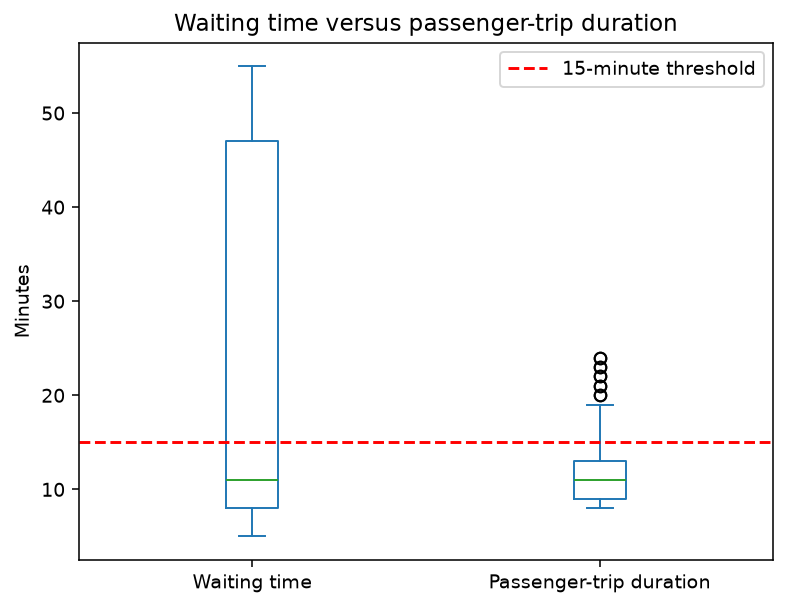

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d = pd.read_csv(dataset_path)
summary = pd.DataFrame({'Waiting time': d['wait_time_minutes'], 'Passenger-trip duration': d['passenger_trip_duration_minutes']})
summary.plot(kind='box')
plt.axhline(15, color='red', linestyle='--', label='15-minute threshold')
plt.title('Waiting time versus passenger-trip duration'); plt.ylabel('Minutes'); plt.legend(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q2_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "Average passenger waiting time is much longer than average passenger-trip duration, while most completed passenger trips last no more than 15 minutes.",
  "insight_value": {
    "comparison": "wait_time_minutes versus passenger_trip_duration_minutes",
    "trip_duration_threshold_minutes": 15
  },
  "plot": {
    "plot_type": "distribution_comparison",
    "title": "Waiting Time and Passenger-Trip Duration",
    "file": "notebook_plots/q2_1.png",
    "description": "The two service-time distributions are compared, with the 15-minute trip threshold shown."
  },
  "question": "How do passenger waiting times compare with passenger-trip durations, and how common are trips lasting 15 minutes or less?",
  "actionable_insight": "Compare the two service-time distributions and the share of short passenger trips.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd = pd.read_csv('trip_events.csv')\nsummary = pd.DataFrame({'Waiting time': d['wait_time_minutes'], 'Passenger-trip duration': d['passenger_trip_duration_minutes']})\nsummary.plot(kind='box')\nplt.axhline(15, color='red', linestyle='--', label='15-minute threshold')\nplt.title('Waiting time versus passenger-trip duration'); plt.ylabel('Minutes'); plt.legend(); plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "request_time",
    "departure_time",
    "dropoff_time",
    "trajectory_id"
  ]
}

### **Question 3**: How does average waiting time vary across drivers, and does the driver-level distribution show distinct groups?

#### Analysis action

Use the driver-day summary rather than only the overall trip average to compare service capacity.

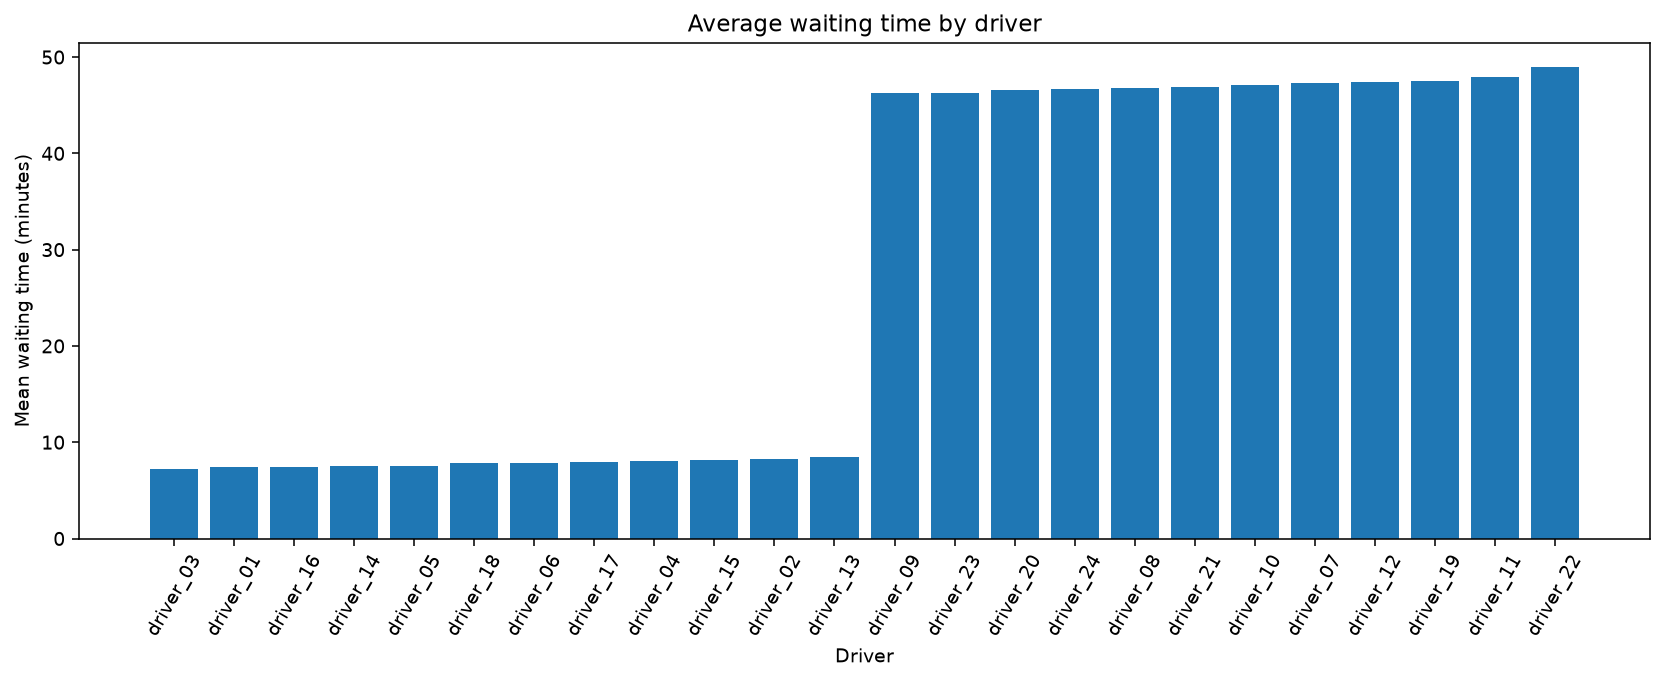

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d = pd.read_csv(user_dataset_path).sort_values('mean_wait_time_minutes')
plt.figure(figsize=(12, 5))
plt.bar(d['driver_id'], d['mean_wait_time_minutes'])
plt.xticks(rotation=60); plt.ylabel('Mean waiting time (minutes)'); plt.xlabel('Driver')
plt.title('Average waiting time by driver'); plt.tight_layout(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q3_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "segmentation",
  "insight": "Driver-level waiting times are strongly polarized: some drivers have short average waits, while another group has substantially longer waits, producing a two-peaked distribution despite the long overall average.",
  "insight_value": {
    "unit_of_analysis": "driver-day",
    "comparison": "mean_wait_time_minutes across drivers"
  },
  "plot": {
    "plot_type": "driver_comparison",
    "title": "Average Waiting Time by Driver",
    "file": "notebook_plots/q3_1.png",
    "description": "Each driver's average waiting time is shown to reveal the separation between short-wait and long-wait groups."
  },
  "question": "How does average waiting time vary across drivers, and does the driver-level distribution show distinct groups?",
  "actionable_insight": "Use the driver-day summary rather than only the overall trip average to compare service capacity.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd = pd.read_csv('driver_day_summary.csv').sort_values('mean_wait_time_minutes')\nplt.figure(figsize=(12, 5))\nplt.bar(d['driver_id'], d['mean_wait_time_minutes'])\nplt.xticks(rotation=60); plt.ylabel('Mean waiting time (minutes)'); plt.xlabel('Driver')\nplt.title('Average waiting time by driver'); plt.tight_layout(); plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "driver_id",
    "request_time",
    "departure_time",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 4)

Taxi demand is concentrated from 08:00 to 16:00 and is lowest during the early morning. Passenger waiting time is substantially longer than passenger-trip duration, although most trips are short. Driver-level waiting times are polarized, with a short-wait group and a much longer-wait group rather than a uniform driver experience.